# Visualization Exercise Sheet

----------------------------------------------------------

In these short questions we will have you work with data from the GALAH spectroscopic survey (https://www.galah-survey.org) of stars in the Milky Way disk, and practice some visualization techniques to help analyze trends in the data.

You will find helpful documentation and examples to help you make the plots at the following graph galleries.
https://python-graph-gallery.com

https://matplotlib.org/stable/plot_types/index.html

**Download the data file 'galahamr.sav' located in the Moodle exercises page, which contains measurements of physical properties of ~7000 nearby stars.**

In [67]:
import numpy as np
from matplotlib import pyplot as plt

In [68]:
#Read in data set
from scipy.io import readsav
filepath = 'galahamr.sav'  #change this to the path on your computer where the file is stored
stars = readsav(filepath)  

In [69]:
#Pull out some attributes of the stars we want to look at and store them in arrays
logg = stars['f']['logg']  #surface gravity   
teff = stars['f']['teff']  #effective temperature
mass = stars['f']['massmean']  #mass
lum = mass**4.  #luminosity for stars 0.43 < Msun < 2
age = stars['f']['agemean'] #age
feh = stars['f']['__fe_h_'] #[Fe/H], a logarithmic Iron abundance
afe = stars['f']['__alpha_fe_']  #[Alpha/Fe], logarithmic relative abundance of alpha elements(O, Si, etc.) relative to Iron

### 1) Consider one version of the Hertzsprung-Russell diagram using effective temperature and surface gravity of the stars ( $T_{eff}$, log(g) ).  Make two types of plots of the stars, with clearly labeled axes and colorbars where suitable: 
* a) a scatter plot with the points colored by age 
* b) a 2D density plot using, e.g. the **kde** package along with the **pcolormesh** routine in matplotlib; or hist2d within matplotlib

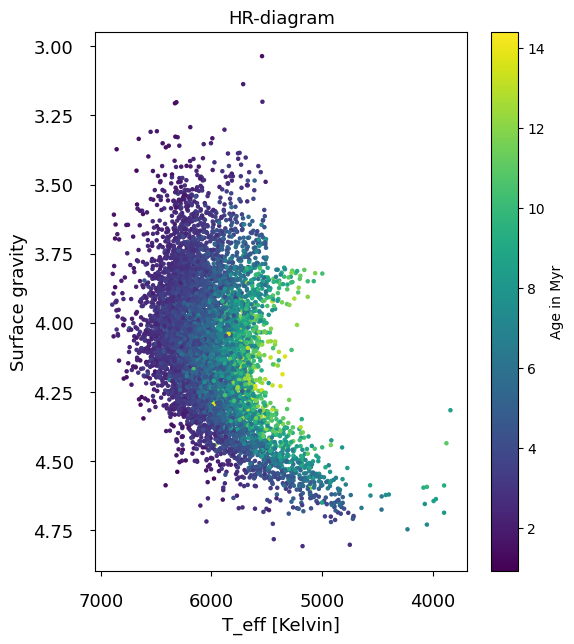

In [70]:
x = teff 
y = logg
#color = age

plt.figure(figsize=(6,7)) # Größe des Plots

plt.gca().invert_xaxis()
plt.gca().invert_yaxis()

plt.tick_params(axis ='x', which ='major', 
               labelsize = 13, pad = 12, 
               colors ='black')

plt.tick_params(axis ='y', which ='major', 
               labelsize = 13, pad = 12, 
               colors ='black')

plt.title("HR-diagram", size=13)
plt.xlabel("T_eff [Kelvin]", size=13) 
plt.ylabel("Surface gravity", size=13)

plt.scatter(x,y, s = 5, c = age)
plt.colorbar().set_label("Age in Myr")

#plt.savefig("HR_diagram.pdf") 
plt.show() # Alles bis jetzt wird generiert 

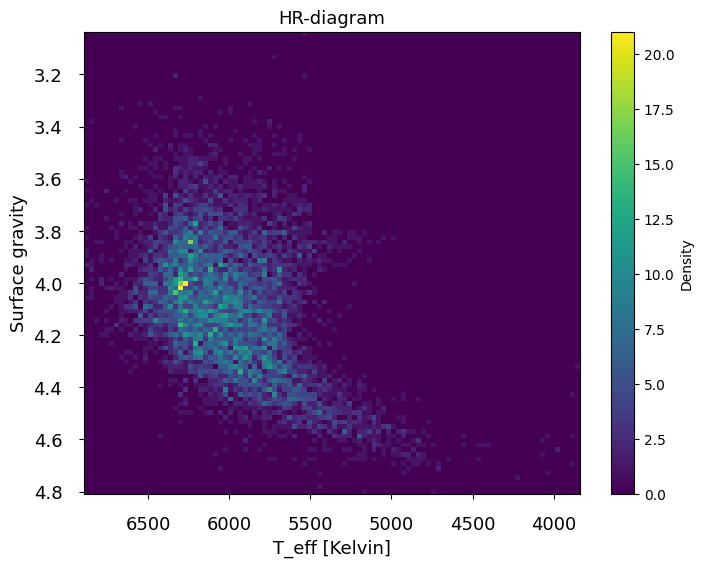

In [71]:
plt.figure(figsize=(8,6))

plt.hist2d(x,y, bins=100)

plt.gca().invert_xaxis()
plt.gca().invert_yaxis()

plt.tick_params(axis ='x', which ='major', 
               labelsize = 13, pad = 12, 
               colors ='black')

plt.tick_params(axis ='y', which ='major', 
               labelsize = 13, pad = 12, 
               colors ='black')

plt.title("HR-diagram", size=13)
plt.xlabel("T_eff [Kelvin]", size=13) 
plt.ylabel("Surface gravity", size=13)

plt.colorbar().set_label("Density")

#plt.savefig("HR_diagram_density.pdf") 
plt.show()

### 2) Use a built-in, or hand-written routine to compute the running average of $T_{eff}$ as a function of $log(g)$.  Overplot this average approximation to the distribution of stars.  It should roughly subdivide the sample into cooler and hotter stars at a given value of $log(g)$.

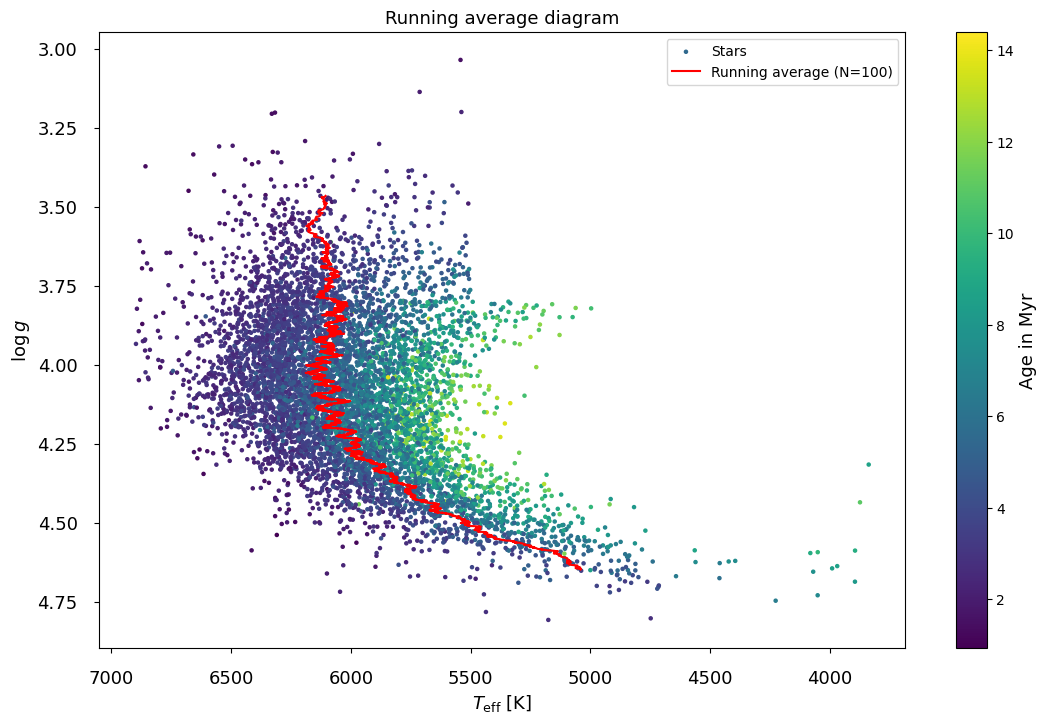

In [72]:
# Auf Indizes von teff zugreifen, 50 nehmen und mean wert in array abspeichern, und wiederholen -> spacial mean 
# Letzter Eintrag: "letzte Zahl" - 50
# Window size variieren 

# for i in range(len(Teff)):
    #np.mean(teff[(i : i + window)])

window = 100 # window size, running average ist 50 

ind_sort = np.argsort(logg) # Indizes sortieren 
teff_sort = teff[ind_sort] # Index der Zahlen zuordnen 
logg_sort = logg[ind_sort]

teff_means = []
logg_points = []

for i in range(len(teff) - window): 
    mean = np.mean(teff_sort[i: i + window])
    teff_means.append(mean)
    mean_index = i + window // 2
    logg_points.append(logg_sort[mean_index])

plt.figure(figsize=(13, 8))

plt.scatter(teff, logg, s = 5, c = age, label = "Stars") # label='Stars' (Legende im Bild!), alpha transparenz
plt.plot(teff_means, logg_points, color = 'red', label = f'Running average (N={window})') # f string: f("...{}") verweist auf Variable -> in {} ! 

plt.title('Running average diagram', size=13)
plt.xlabel(r'$T_{\rm eff}$ [K]', size=13)
plt.ylabel(r'$\log g$', size=13)
plt.legend()

plt.tick_params(axis ='x', which ='major', 
               labelsize = 13, pad = 12, 
               colors ='black')

plt.tick_params(axis ='y', which ='major', 
               labelsize = 13, pad = 12, 
               colors ='black')

plt.gca().invert_xaxis()   
plt.gca().invert_yaxis() 

plt.colorbar().set_label("Age in Myr", size=13)

#plt.savefig("HR_diagram_running_average.pdf") 
plt.show()

### 3) [OPTIONAL]  Compute the mean and standard deviation ($\sigma$) of the ages of the cool and hot star sub-samples

* What percent of stars have an age that is within $1-\sigma$ of the mean ages of *both* the cool and hot star sub-samples?  e.g., the fraction of stars that have ages within
 
$(mean(age_{hot}) +\sigma(age_{hot}))$ $\leq age \leq$ $(mean(age_{cool}) -\sigma(age_{cool}))$

In [73]:
# hot mean age ca. 3,6 Gyr
# cold mean age ca. 6,7 Gyr 

### 4) Create two versions of a *weighted* 2D density distribution of the sample of stars in the plane of **[Fe/H]** as a function of **age**:
* a) One where the density distribution is weighted by the mass of the stars
* b) One where the density distribution is weighted by the luminosity of the stars

Compute the weighted average metallicity and age for both cases and indicate them on the density distributions.

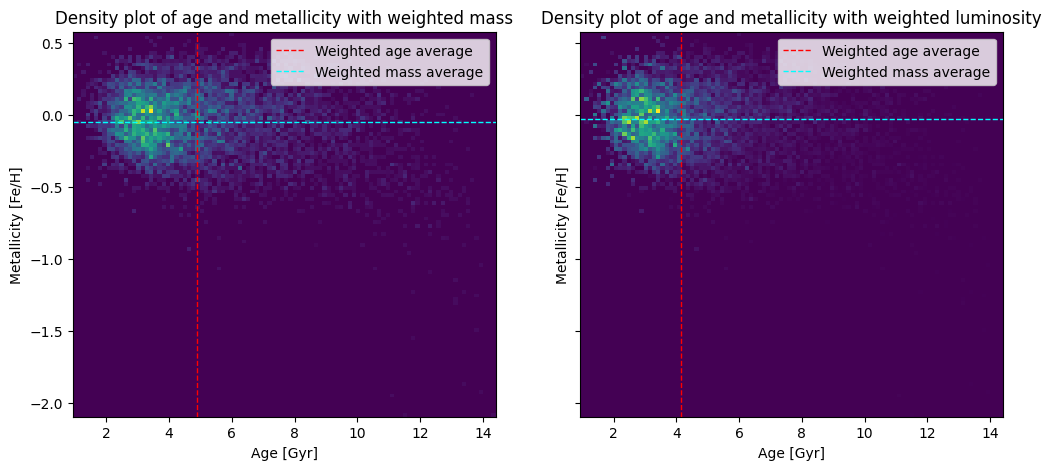

In [74]:
# sum = np.sum(teff), np.mean(), np.std()

# for i in range(len(Teff)):
    #np.mean(teff[(i : i + window)])

#np.mean()

x = age.copy()
y = feh.copy()

w_mass = mass.copy()
w_lum = lum.copy()

metal_avg_w_mass = np.sum(w_mass*y)/np.sum(w_mass)
age_avg_w_mass = np.sum(w_mass*x)/np.sum(w_mass)

metal_avg_w_lum = np.sum(w_lum*y)/np.sum(w_lum)
age_avg_w_lum = np.sum(w_lum*x)/np.sum(w_lum)

fig, axes = plt.subplots(1, 2, figsize=(12,5), sharex = True, sharey = True) # Gleiche ticks & scales, aber eigene labels

             
plt_1 = axes[0].hist2d(x, y, weights = w_mass, bins = 100) 
axes[0].set_title("Density plot of age and metallicity with weighted mass")
axes[0].set_xlabel("Age [Gyr]")
axes[0].set_ylabel("Metallicity [Fe/H]")

axes[0].axvline(age_avg_w_mass, label = "Weighted age average", color='red', ls='--', lw=1) # gestrichelte Linie: (ls='--', lw=1)
axes[0].axhline(metal_avg_w_mass, label = "Weighted mass average", color='cyan', ls='--', lw=1)
axes[0].legend()
#axes[0].plt.colorbar().set_label("Density") # geht nicht? 
#plt.savefig("denstiy_plot_mass.pdf") 
     
plt_2 = axes[1].hist2d(x, y, weights = w_lum, bins = 100)
axes[1].set_title("Density plot of age and metallicity with weighted luminosity")
axes[1].set_xlabel("Age [Gyr]")
axes[1].set_ylabel("Metallicity [Fe/H]")

axes[1].axvline(age_avg_w_lum, label = "Weighted age average", color='red', ls='--', lw=1)
axes[1].axhline(metal_avg_w_lum, label = "Weighted mass average", color='cyan', ls='--', lw=1)
axes[1].legend()
#axes[1].plt.colorbar().set_label("Density")
#plt.savefig("denstiy_plot_lum.pdf") 

plt.show()